# Assignment 2 — Predictive data mining report

<p class="lead">
Act as the lead data miner for a real-estate analytics firm: turn agents' written property descriptions into a numeric Text Appeal Score with sentiment analysis, combine it with the structured facts about each home in a multiple linear regression, test the model on homes it has never seen, and report what drives price to the firm's board.
</p>

*Adapted from the DATA 300 syllabus, Assignment 2 (Predictive data mining report). Brief rewritten for this classroom; the analysis runs offline in local JupyterLab.*

> **Graded work: Assignment 2 (6%, CLO 1, 2, 3 and 4)**
>
> - **Set:** Monday 16 November (Day 4), after the data-mining lecture.
> - **Due:** **Sunday 22 November 2026, 23:59 China Standard Time**.
> - **Submit:** one PDF, `YourLastName_DATA300_Assignment2.pdf`, to the **DATA 300: Assignment 2** drop-box on **GAP (Moodle)**.
> - **Work:** individual. Online support is available during the post-class week.

This notebook is both the **brief** (read it all first) and your **starter notebook**. Save your own copy before you change anything: **File → Save Notebook As…** → `YourLastName_DATA300_Assignment2.ipynb`, in the same folder as this notebook so that `data/nltk_data` is found.

---

## The scenario

You are the lead data miner at **UrbanTrend Real Estate Analytics**. The firm wants an automated way to estimate the market value (**Price**, in US dollars) of a home. For each past sale it has:

| Data | Type | Columns |
|---|---|---|
| Facts about the home | **Structured** | `SqFt` (floor area, square feet), `Bedrooms`, `Age` (years) |
| The agent's written description | **Unstructured** | `Description` |
| What the home sold for | Target | `Price` (US dollars) |

Analysts at the firm have always ignored the descriptions because a model cannot read sentences. Your job is to change that: use **text mining** (VADER sentiment analysis) to turn each description into a number, the **Text Appeal Score**, and test whether adding it to a **multiple linear regression** improves the price predictions.

> **About the data**
>
> The 500 home sales are **synthetic**: the first code cell generates them with a fixed random seed, exactly as in the course syllabus, so everyone has the same data. They describe no real homes or agents.

---

## What you must do

| Part | Task |
|---|---|
| 1 | Complete and run this notebook so that it produces **Figure 1**, **Figure 2**, **Table 1** (text-mining output), and the **Model A** and **Model B** results, as specified below |
| 2 | Write a **business report** for the board with the five required sections |
| 3 | Export the report and the executed notebook to PDF, combine them, and submit on GAP |

Every code cell already runs. Three cells are **starting points** that you must finish; the text above each says exactly what the finished output must show. The changes are small and use only what you saw in the Day 3 text-mining lab and today's lectures.

---

## Part 1: The analysis

### Setup

Run the next two cells first. The first points NLTK at the bundled VADER lexicon (no internet needed); the second loads the libraries.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 120)

### Step 1: Generate the data (do not change this cell)

The cell builds the dataset the same way as the syllabus. Each home's price is built from its floor area, age and bedrooms. Then each home gets one of three agent descriptions: about 20% get an enthusiastic "luxury" description and a price premium, about 20% get a "fixer-upper" description and a price penalty, and the rest get a neutral "family home" description. Finally, random market noise is added. **Do not change the seed or the numbers**: your results must match everyone else's.

In [3]:
# 1. Simulate the real-estate dataset (seed fixed so everyone gets the same 500 homes)
np.random.seed(101)
n = 500
sqft = np.random.normal(2200, 600, n)
age = np.random.uniform(1, 60, n)
beds = np.random.randint(2, 6, n)

# Baseline price from the structured facts
price = (sqft * 150) - (age * 800) + (beds * 15000)

# The agent's description (unstructured text), with a premium or a penalty
descriptions = []
for i in range(n):
    rand_val = np.random.rand()
    if rand_val > 0.8:
        descriptions.append("Absolutely stunning! Fully renovated with luxury finishes, granite, "
                            "and beautiful hardwood. A dream home.")
        price[i] += 45000   # premium for luxury
    elif rand_val < 0.2:
        descriptions.append("Needs significant work. Major fixer-upper. Roof is old and interior "
                            "requires complete cosmetic updates. Sold as-is.")
        price[i] -= 35000   # penalty for needing repairs
    else:
        descriptions.append("Nice family home in a quiet neighborhood. Standard features, "
                            "well maintained. Ready to move in.")

# Market noise
price += np.random.normal(0, 15000, n)

df = pd.DataFrame({"SqFt": sqft, "Bedrooms": beds, "Age": age, "Description": descriptions, "Price": price})

print("--- Raw data snapshot (structured and unstructured) ---")
print("Homes:", len(df))
df.head()

--- Raw data snapshot (structured and unstructured) ---
Homes: 500


,SqFt,Bedrooms,Age,Description,Price
0,3824.109904,2,32.163739,"Absolutely stunning! Fully renovated with luxury finishes, granite...",632771.592606
1,2576.879625,3,59.017390,"Nice family home in a quiet neighborhood. Standard features, well ...",359645.538748
2,2744.781668,2,50.610424,"Nice family home in a quiet neighborhood. Standard features, well ...",379984.232018
3,2502.295452,4,24.534343,Needs significant work. Major fixer-upper. Roof is old and interio...,394938.959600
4,2590.670769,2,21.470797,Needs significant work. Major fixer-upper. Roof is old and interio...,380233.008617


### Step 2: Exploratory data analysis

**Figure 1 (complete):** a scatter plot of `SqFt` against `Price`.

**Figure 2 (starting point):** the finished figure must show **one box plot of `Price` for each number of bedrooms** (2, 3, 4 and 5), side by side, with the title `Figure 2: Price distribution by number of bedrooms`, the x-axis label `Bedrooms` and the y-axis label `Price ($)`. The starting point draws a single box for all homes. Add the bedrooms on the x-axis and fix the title and labels.

> **Reading a box plot**
>
> The line inside the box is the **median**; the box spans the middle half of the values (the **interquartile range**); the whiskers reach the furthest values within 1.5 × IQR of the box; points beyond them are drawn individually.

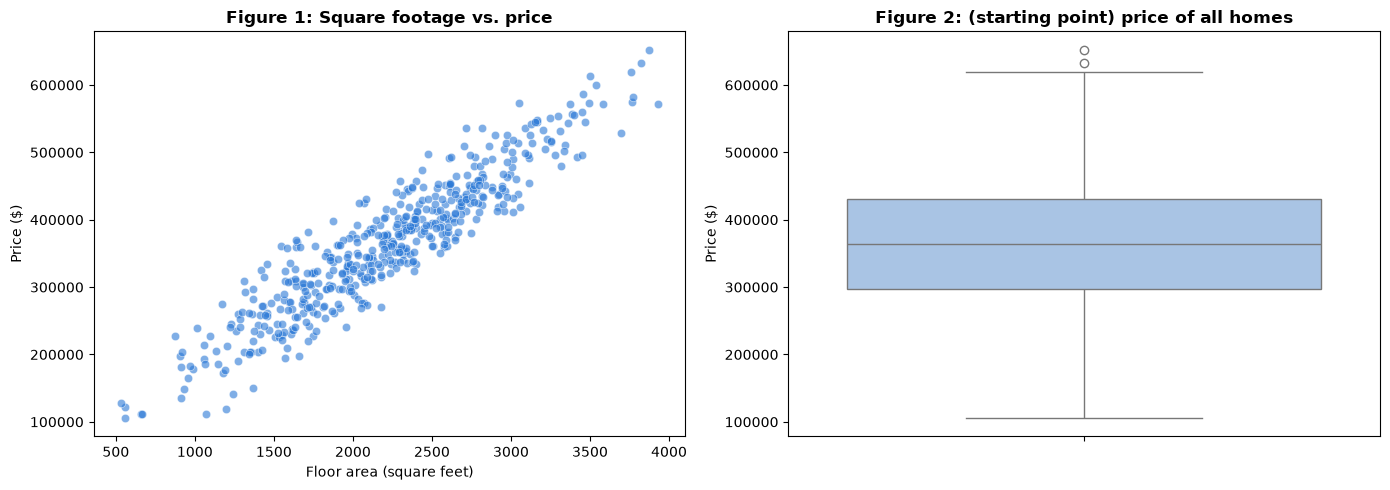

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Figure 1 (complete)
sns.scatterplot(data=df, x="SqFt", y="Price", alpha=0.6, color="#2a78d6", ax=axes[0])
axes[0].set_title("Figure 1: Square footage vs. price", fontweight="bold")
axes[0].set_xlabel("Floor area (square feet)")
axes[0].set_ylabel("Price ($)")

# Figure 2 (starting point): one box for all homes. Change it as described above.
sns.boxplot(data=df, y="Price", color="#9fc3ee", ax=axes[1])
axes[1].set_title("Figure 2: (starting point) price of all homes", fontweight="bold")
axes[1].set_ylabel("Price ($)")

plt.tight_layout()
plt.show()

### Step 3: Text mining: the Text Appeal Score

VADER gives every text a **compound** score from −1 (very negative) to +1 (very positive). That score becomes the new feature `Text_Appeal_Score`.

**Table 1 (starting point):** the finished cell must add a column `Text_Appeal_Score` to `df` that holds the VADER compound score of **every** home's description, and then show the first rows of `Description`, `Text_Appeal_Score` and `Price`. The starting point scores **only the first description**. Use the function `text_appeal` with pandas `.apply(...)`, as in the Day 3 text-mining lab.

After you finish the cell, look at **all three** descriptions and their scores, not only the first rows: the second print-out lists each distinct description once with its score.

In [5]:
analyzer = SentimentIntensityAnalyzer()


def text_appeal(text):
    """VADER compound score of one description, from -1 (negative) to +1 (positive)."""
    return analyzer.polarity_scores(text)["compound"]


# Starting point: the score of the first description only
print("First description:", df.loc[0, "Description"])
print("Its Text Appeal Score:", text_appeal(df.loc[0, "Description"]))

# TODO: create df["Text_Appeal_Score"] for every row here (one line).

if "Text_Appeal_Score" in df.columns:
    print("\n--- Table 1: data after text-mining feature engineering ---")
    print(df[["Description", "Text_Appeal_Score", "Price"]].head().to_string())
    print("\n--- Each distinct description and its score ---")
    distinct = df.groupby("Description")["Text_Appeal_Score"].agg(["first", "count"])
    distinct.columns = ["Text_Appeal_Score", "homes"]
    print(distinct.sort_values("Text_Appeal_Score").to_string())
else:
    print("\nText_Appeal_Score has not been created yet.")

First description: Absolutely stunning! Fully renovated with luxury finishes, granite, and beautiful hardwood. A dream home.
Its Text Appeal Score: 0.8436

Text_Appeal_Score has not been created yet.


### Step 4: Predictive regression

Both models use the same **80/20 train/test split** (`random_state=42`), are fitted on the training homes only, and are judged on the 100 **test** homes they never saw.

**Model A (complete):** structured features only (`SqFt`, `Bedrooms`, `Age`). This is the firm's current approach, and your baseline.

In [6]:
def fit_and_evaluate(features, label):
    """Fit a linear regression on the training homes; report test R², test RMSE and coefficients."""
    X = df[features]
    y = df["Price"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"--- {label}: performance on the hidden test homes ---")
    print(f"Test R-squared: {r2:.4f}")
    print(f"Test RMSE (typical error): ${rmse:,.2f}")
    print(f"\n--- {label}: coefficients (financial impact of one more unit) ---")
    coef_df = pd.DataFrame({"Feature": features, "Coefficient ($ per unit)": model.coef_})
    coef_df["Coefficient ($ per unit)"] = coef_df["Coefficient ($ per unit)"].apply(lambda x: f"${x:,.2f}")
    print(coef_df.to_string(index=False))
    return {"Test R²": round(r2, 4), "Test RMSE ($)": round(rmse, 2)}


model_a = fit_and_evaluate(["SqFt", "Bedrooms", "Age"], "Model A (structured only)")

--- Model A (structured only): performance on the hidden test homes ---
Test R-squared: 0.9165
Test RMSE (typical error): $29,923.35

--- Model A (structured only): coefficients (financial impact of one more unit) ---
 Feature Coefficient ($ per unit)
    SqFt                  $147.68
Bedrooms               $15,304.06
     Age                 $-814.49


**Model B (starting point):** the finished cell must fit the same model **with `Text_Appeal_Score` added** as a fourth feature, and print the comparison table of Model A and Model B. The starting point uses the structured features only, so for now Model B repeats Model A. Add the text feature to the list.

In [7]:
features_b = ["SqFt", "Bedrooms", "Age"]   # TODO: add "Text_Appeal_Score"

model_b = fit_and_evaluate(features_b, "Model B (structured + text)")

print("\n--- Model comparison on the same test homes ---")
print(pd.DataFrame({"Model A: structured only": model_a, "Model B: structured + text": model_b}).T.to_string())

--- Model B (structured + text): performance on the hidden test homes ---
Test R-squared: 0.9165
Test RMSE (typical error): $29,923.35

--- Model B (structured + text): coefficients (financial impact of one more unit) ---
 Feature Coefficient ($ per unit)
    SqFt                  $147.68
Bedrooms               $15,304.06
     Age                 $-814.49

--- Model comparison on the same test homes ---
                            Test R²  Test RMSE ($)
Model A: structured only     0.9165       29923.35
Model B: structured + text   0.9165       29923.35


> **Check before you write**
>
> - Restart the kernel and run every cell (**Kernel → Restart Kernel and Run All Cells**). No errors.
> - Figure 2 shows four boxes, one per number of bedrooms, with the required title and labels.
> - Table 1 shows a `Text_Appeal_Score` for every row, and the list of the three distinct descriptions with their scores appears.
> - Model B lists **four** coefficients, including `Text_Appeal_Score`, and the comparison table shows two different rows.
> - You may add a short, labelled cell for any extra number you quote in the report (for example the median price for each bedroom count).

---

## Part 2: The business report

Write the report in **Word** (or another editor that saves PDF) for the **executive board** of UrbanTrend Real Estate Analytics. Use the **five headings below exactly**, in this order. Write connected paragraphs, not lists of answers; only Section 5 uses bullet points. Quote the numbers you use, with units, and refer to the evidence by name (Figure 1, Table 1, Model B…).

### 1. Executive Summary

*One paragraph.* The purpose of the project, the two kinds of data used (structured facts and unstructured agent descriptions), and what the predictive model is for.

### 2. Exploratory Data Analysis

*One or two paragraphs*, based on Figures 1 and 2.

- Describe the relationship between floor area and price in Figure 1: direction, strength, shape.
- From Figure 2: do more bedrooms always mean a higher **median** price? How does the **spread** of prices (the height of the boxes) change from 2 to 5 bedrooms?

### 3. Text Mining Methodology and Value

*One or two paragraphs.*

- Explain, for a non-technical board, what Step 3 did: how a written description became a number between −1 and +1.
- Using the list of distinct descriptions and their scores: which description scored highest and which lowest? Is the score for the "fixer-upper" description negative, as you might expect? Explain why a general-purpose sentiment lexicon might score it the way it does.
- Why is it worth turning the descriptions into a number **before** building a pricing model? Use the comparison of Model A and Model B.

### 4. Predictive Analytics Results

*Two paragraphs*, based on Model B (and Model A for comparison).

- **Accuracy:** state Model B's test R² and RMSE and explain what they mean for predicting the price of homes the model has not seen. How much did adding the text score improve on Model A?
- **Business drivers:** from Model B's coefficients, how much value is associated with one extra bedroom, and how much with each extra year of age, holding the other features fixed?
- **The value of text:** the Text Appeal Score runs from −1 to +1, so a change of 1.0 is the jump from a neutral to a highly positive description. Using its coefficient, what is that jump associated with in dollars? Then use the actual scores of the three descriptions to say how large the predicted gap between a "fixer-upper" and a "luxury" description really is. Remember that these are associations, not proof that rewriting a description would raise a price.

### 5. Strategic Recommendations

*Two bullet points*, each justified by your results: practical advice for the firm's agents (for example, how much effort to put into descriptions; which features of a home to stress in marketing) or for the firm's modelling team (for example, how to improve the text feature).

> **Good practice from today's lectures**
>
> Lead with the finding, not the method. Report test results, not training results. Say "is associated with", not "causes". Name the units (dollars, square feet, years).

---

## Part 3: Export and submit

| Step | What to do | File name |
|---|---|---|
| 1 | Save your Word report as PDF (five sections, headings exactly as above, your name and student ID on the first page) | `LastName_Assignment2_Report.pdf` |
| 2 | In JupyterLab, run **Kernel → Restart Kernel and Run All Cells** and check that every figure and table is visible | |
| 3 | Export the notebook: **File → Print**, destination **Save as PDF**, with **Background graphics** ticked | `LastName_Assignment2_JupyterLab.pdf` |
| 4 | Combine the two PDFs into one, **report first**, notebook second as an appendix. See [Combining PDFs without internet](setup.md#combining-pdfs-without-internet) | `YourLastName_DATA300_Assignment2.pdf` |
| 5 | Log in to **GAP (Moodle)**, open the **DATA 300: Assignment 2** drop-box, upload the combined PDF and click **Submit** before the deadline | |

---

## How it is marked

The assignment is marked out of 100 with the course's Assignment 2 rubric, then scaled to its 6% weight.

| Criterion | Points | What earns them here |
|---|---|---|
| **CLO 1**: principles of descriptive, predictive and prescriptive analytics | 20 | A clear statement of the predictive problem and of how the model supports pricing decisions; recommendations that follow from the evidence |
| **CLO 2**: visualisation and modelling tools that communicate for decisions | 20 | Correct Figures 1 and 2 with the required titles and labels, read correctly in Section 2 |
| **CLO 3**: data and text mining in structured and unstructured data | 20 | A working Text Appeal Score for every home; an accurate, critical explanation of what the score captures and misses |
| **CLO 4**: developing and evaluating predictive models | 20 | Model B built correctly; test R² and RMSE quoted and interpreted; coefficients read correctly; improvement over Model A explained |
| **Professional formatting** | 10 | The five headings, a combined PDF in the right order with the right file name, APA-style citations for any sources |
| **Academic writing** | 10 | Clear, organised paragraphs for a board audience; correct terms; two justified recommendations |

Each criterion is judged on a scale from *exemplary* (full points) through *excellent*, *proficient*, *developing* and *unsatisfactory*; a missing submission scores 0.

---

## Final checklist

- [ ] My notebook is saved as `YourLastName_DATA300_Assignment2.ipynb` and runs from top to bottom without errors.
- [ ] Figure 2, Table 1 and Model B are finished as specified.
- [ ] My report has the five headings exactly, quotes test results with units, and ends with two justified recommendations.
- [ ] I have not claimed that a description **causes** a higher price.
- [ ] One PDF, `YourLastName_DATA300_Assignment2.pdf`, report first, uploaded to GAP by **Sunday 22 November, 23:59 China Standard Time**.